# Linear regression: does fire and weather information improve next-day PM2.5 prediction in Singapore?

This notebook follows the flow of the course's *Wine prediction* example (Week 3), applied to project topic 1.2. Run the cells in order. It reads `data/processed/model_table.csv`, which `data_transform.ipynb` builds from the raw downloads.

**Question.** For NEA and public-health advisories, can regional satellite fire detections and local weather observed at hour *t* improve the prediction of Singapore's island-mean PM2.5 at *t + 24 h*, beyond persistence and the daily cycle, for 15 Sep – 31 Oct 2023?

**Declared before any model is fitted** (rubric §4):
- **Outcome** `y`: island-mean 1-hour PM2.5 (µg/m³) 24 hours after the forecast time.
- **Metrics:** RMSE and MAE in µg/m³ (an interpretable error scale), out-of-sample R², and **skill versus persistence** = 1 − SSE(model) / SSE(persistence). Skill answers "beyond persistence" directly: above 0 means the model beats "tomorrow = today".
- **Split by time.** Training uses forecast times up to 14 Oct. The **final test** uses forecast times 16–30 Oct and is not touched until §9. Forecast times on 15 Oct are dropped (an *embargo*), so no training target falls inside the test period.
- **Model selection** uses rolling-origin validation inside the training period (§8), never the test set.

The models establish **association and predictive value, not causation**: a fire term that helps prediction does not show that those fires produced that PM2.5.

# 1. Packages and data

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.graphics.tsaplots import plot_acf
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SGT = "Asia/Singapore"
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

table = pd.read_csv("data/processed/model_table.csv", index_col="timestamp")
table.index = pd.to_datetime(table.index, utc=True).tz_convert(SGT)
table["target_time"] = pd.to_datetime(table["target_time"], utc=True).dt.tz_convert(SGT)

# split dates, declared up front
TRAIN_LAST_TARGET = pd.Timestamp("2023-10-15 23:00", tz=SGT)   # training targets must be <= this
TEST_START = pd.Timestamp("2023-10-16 00:00", tz=SGT)           # first test forecast time
TEST_LAST_ORIGIN = pd.Timestamp("2023-10-30 23:00", tz=SGT)     # its target is the last hour of data

# weather models are only used once weather covers (almost) the whole window
WEATHER_OK = table["temp"].notna().mean() > 0.9
print(table.shape, "| weather coverage:", f"{table['temp'].notna().mean():.0%}", "| weather models used:", WEATHER_OK)

(1128, 31) | weather coverage: 98% | weather models used: True


## Missing values

In [33]:
missing = pd.DataFrame({"missing": table.isna().sum(), "pct": (table.isna().mean() * 100).round(1)})
missing[missing["missing"] > 0]

,missing,pct
pm25_mean,55,4.9
pm25_lag0,55,4.9
pm25_lag24,78,6.9
y,79,7.0
temp,20,1.8
rh,20,1.8
rain_1h,20,1.8
ws_ms,20,1.8
u,20,1.8
v,20,1.8


PM2.5 is missing for whole hours, most of 8 Oct (inside the haze episode) included. A missing hour removes a row twice: once as a target (`y`) and once as an input (`pm25_lag0`). Fire windows are NaN for the first 24–48 h because fires before 15 Sep were not downloaded. Rows with any missing model input are dropped below. They are never filled in, so no value is invented.

# 2. Explore the training period

Only the training period is explored here, so nothing seen in the test period can influence how the models are built.

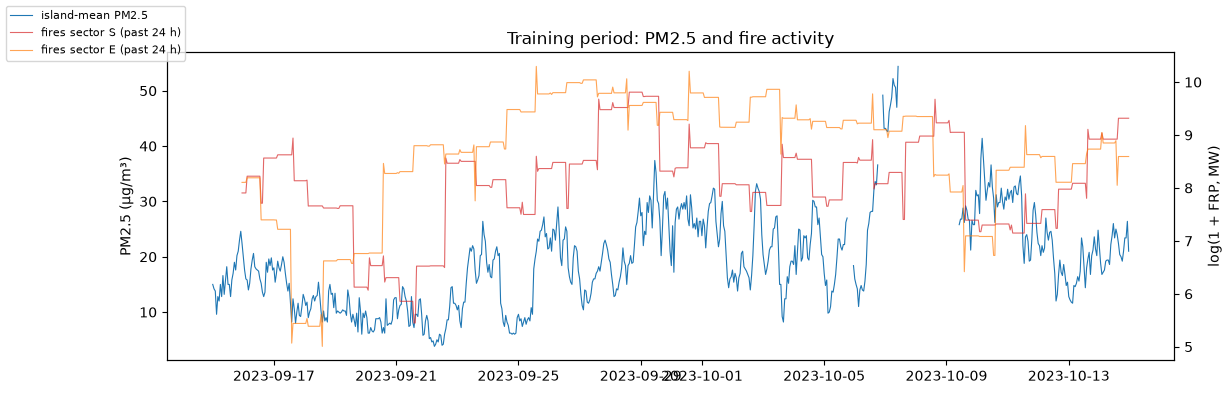

In [34]:
train_all = table[table["target_time"] <= TRAIN_LAST_TARGET]

fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.plot(train_all.index, train_all["pm25_mean"], lw=0.8, color="tab:blue", label="island-mean PM2.5")
ax1.set_ylabel("PM2.5 (µg/m³)")
ax2 = ax1.twinx()
for s, c in [("S", "tab:red"), ("E", "tab:orange")]:
    ax2.plot(train_all.index, train_all[f"frp_{s}_24h"], lw=0.8, color=c, alpha=0.7, label=f"fires sector {s} (past 24 h)")
ax2.set_ylabel("log(1 + FRP, MW)")
fig.legend(loc="upper left", fontsize=8); ax1.set_title("Training period: PM2.5 and fire activity")
fig.savefig(FIG / "train_timeseries.png", dpi=150, bbox_inches="tight"); plt.show()

## Which fire sectors carry information?

In [35]:
sectors = ["N", "E", "S", "W"]
frp_total = pd.Series({s: np.expm1(train_all[f"frp_{s}_24h"]).sum() for s in sectors})
sector_activity = pd.DataFrame({
    "share of training-period FRP (%)": frp_total / frp_total.sum() * 100,
    "hours with any fire (%)": [(train_all[f"frp_{s}_24h"] > 0).mean() * 100 for s in sectors],
}).round(1)
SECTORS_USED = list(sector_activity.index[sector_activity["share of training-period FRP (%)"] >= 5])
display(sector_activity)
print("sectors used in the models:", SECTORS_USED)

,share of training-period FRP (%),hours with any fire (%)
N,0.2,81.2
E,64.4,96.8
S,34.5,96.8
W,1.0,96.8


sectors used in the models: ['E', 'S']


The rule keeps a sector if it holds at least 5% of the training-period fire radiative power. It uses only the training period and never looks at PM2.5, so it cannot leak test information. In Sep–Oct 2023 almost all fire intensity is in the **S** sector (South Sumatra) and the **E** sector (Kalimantan). The N and W sectors have small fires most hours but a negligible share of the total, so their columns would add parameters with little information.

## Relationships among the variables

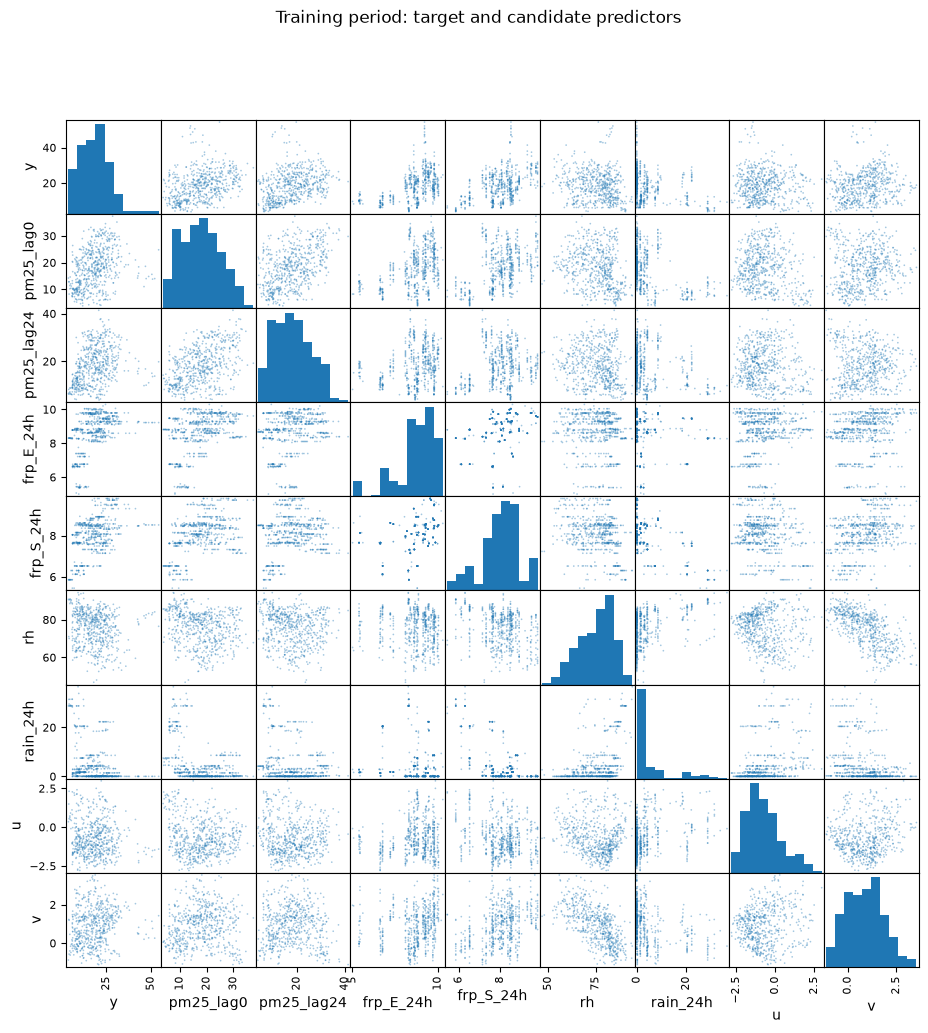

,y,pm25_lag0,pm25_lag24,frp_E_24h,frp_S_24h,rh,rain_24h,u,v
y,1.00,0.41,0.33,0.33,0.44,-0.14,-0.33,-0.09,0.08
pm25_lag0,0.41,1.00,0.41,0.28,0.33,-0.16,-0.43,-0.20,0.02
pm25_lag24,0.33,0.41,1.00,0.23,0.23,-0.14,-0.27,-0.11,-0.01
frp_E_24h,0.33,0.28,0.23,1.00,0.37,-0.08,-0.16,0.13,0.23
frp_S_24h,0.44,0.33,0.23,0.37,1.00,-0.30,-0.62,-0.26,0.38
rh,-0.14,-0.16,-0.14,-0.08,-0.30,1.00,0.40,-0.13,-0.64
rain_24h,-0.33,-0.43,-0.27,-0.16,-0.62,0.40,1.00,0.36,-0.32
u,-0.09,-0.20,-0.11,0.13,-0.26,-0.13,0.36,1.00,0.12
v,0.08,0.02,-0.01,0.23,0.38,-0.64,-0.32,0.12,1.00


In [36]:
explore_cols = ["y", "pm25_lag0", "pm25_lag24"] + [f"frp_{s}_24h" for s in SECTORS_USED]
if WEATHER_OK:
    explore_cols += ["rh", "rain_24h", "u", "v"]
pd.plotting.scatter_matrix(train_all[explore_cols].dropna(), figsize=(11, 11), s=6, alpha=0.4, diagonal="hist")
plt.suptitle("Training period: target and candidate predictors"); plt.show()
train_all[explore_cols].corr().round(2)

## Why not model log PM2.5?

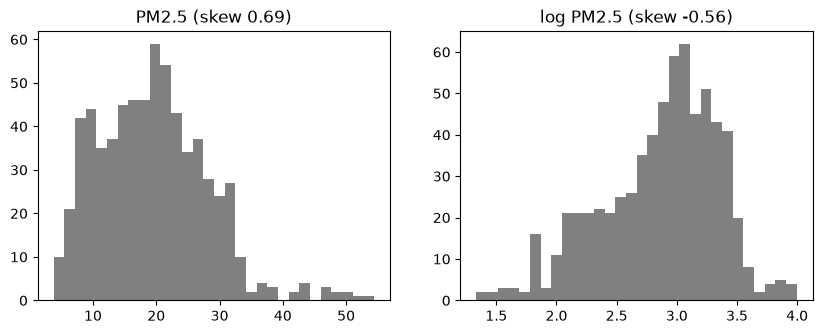

In [37]:
y_train_all = train_all["y"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(y_train_all, bins=30, color="grey"); axes[0].set_title(f"PM2.5 (skew {y_train_all.skew():.2f})")
axes[1].hist(np.log(y_train_all), bins=30, color="grey"); axes[1].set_title(f"log PM2.5 (skew {np.log(y_train_all).skew():.2f})")
plt.show()

The wine example models *log* price because prices are strongly right-skewed. PM2.5 here is only moderately skewed, and an error in µg/m³ is easier to read for a health advisory, so the main models use the **raw scale**. A log-scale version of the largest model is fitted once in §9 as a sensitivity check. As the wine notebook says, the regression diagnostics (§7), not these histograms, decide whether the assumptions are reasonable.

# 3. Training and evaluation sets

In [38]:
season = "hour_sin + hour_cos + is_weekend"
f_base = "pm25_lag0 + pm25_lag24 + " + season
f_fire_terms = " + ".join(f"frp_{s}_24h" for s in SECTORS_USED)
f_transport_terms = " + ".join(f"transport_{s}" for s in SECTORS_USED)

formulas = {"Season only": "y ~ " + season, "Baseline (persistence + season)": "y ~ " + f_base}
if WEATHER_OK:
    f_weather = f_base + " + temp + rh + rain_24h + u + v"
    formulas["+ Weather"] = "y ~ " + f_weather
    formulas["+ Weather + Fire"] = "y ~ " + f_weather + " + " + f_fire_terms
    formulas["+ Weather + Fire + Transport"] = "y ~ " + f_weather + " + " + f_fire_terms + " + " + f_transport_terms
else:
    formulas["+ Fire"] = "y ~ " + f_base + " + " + f_fire_terms
FULL = list(formulas)[-1]

# every model is fitted on the same rows, so nested comparisons are valid
used_cols = sorted({v for f in formulas.values() for v in f.replace("y ~", "").replace(" ", "").split("+")} | {"y"})
complete = table.dropna(subset=used_cols)

train = complete[complete["target_time"] <= TRAIN_LAST_TARGET]
test = complete[(complete.index >= TEST_START) & (complete.index <= TEST_LAST_ORIGIN)]
embargo = complete[(complete["target_time"] > TRAIN_LAST_TARGET) & (complete.index < TEST_START)]

assert train["target_time"].max() < test.index.min(), "a training target overlaps the test period"
print(f"training rows: {len(train)}  ({train.index.min():%d %b %H:%M} -> {train.index.max():%d %b %H:%M})")
print(f"embargoed rows (15 Oct forecasts, unused): {len(embargo)}")
print(f"test rows: {len(test)}  ({test.index.min():%d %b %H:%M} -> {test.index.max():%d %b %H:%M})")
print(f"rows dropped for missing values: {len(table) - len(complete)} of {len(table)}")
for name, f in formulas.items():
    print(f"{name:32s} {f}")

training rows: 587  (16 Sep 00:00 -> 14 Oct 23:00)
embargoed rows (15 Oct forecasts, unused): 24
test rows: 334  (16 Oct 00:00 -> 30 Oct 23:00)
rows dropped for missing values: 183 of 1128
Season only                      y ~ hour_sin + hour_cos + is_weekend
Baseline (persistence + season)  y ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend
+ Weather                        y ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend + temp + rh + rain_24h + u + v
+ Weather + Fire                 y ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend + temp + rh + rain_24h + u + v + frp_E_24h + frp_S_24h
+ Weather + Fire + Transport     y ~ pm25_lag0 + pm25_lag24 + hour_sin + hour_cos + is_weekend + temp + rh + rain_24h + u + v + frp_E_24h + frp_S_24h + transport_E + transport_S


The wine example trains on 1952–1978 and evaluates on later vintages. The same idea applies here, but by hour: the model is trained on the past and judged on the future. A random split would let the model see the hours on either side of a test hour, which makes hourly PM2.5 look far more predictable than it really is.

# 4. Simple linear regression

## Model 1: next-day PM2.5 and today's PM2.5

In [39]:
model_lag0 = smf.ols("y ~ pm25_lag0", data=train).fit()
print(model_lag0.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     79.28
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           6.76e-18
Time:                        21:29:13   Log-Likelihood:                -2042.2
No. Observations:                 587   AIC:                             4088.
Df Residuals:                     585   BIC:                             4097.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     11.4227      0.866     13.193      0.0

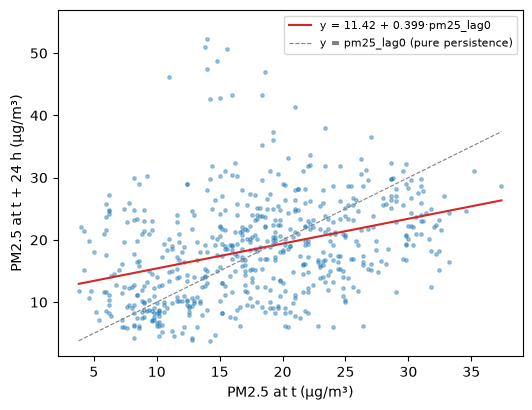

In [40]:
b0, b1 = model_lag0.params
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(train["pm25_lag0"], train["y"], s=6, alpha=0.4)
xs = np.linspace(train["pm25_lag0"].min(), train["pm25_lag0"].max(), 50)
ax.plot(xs, b0 + b1 * xs, color="tab:red", label=f"y = {b0:.2f} + {b1:.3f}·pm25_lag0")
ax.plot(xs, xs, ls="--", color="grey", lw=0.8, label="y = pm25_lag0 (pure persistence)")
ax.set_xlabel("PM2.5 at t (µg/m³)"); ax.set_ylabel("PM2.5 at t + 24 h (µg/m³)"); ax.legend(fontsize=8)
plt.show()

A slope below 1 means tomorrow is predicted to move part of the way back towards the average (regression to the mean). A slope of exactly 1 with intercept 0 would be pure persistence. As the wine notebook stresses, a significant p-value says the slope is not zero *in this sample*. It does not show that the model predicts the future well, which §8 and §9 test.

## Compute training R² directly

In [41]:
sse = np.sum(model_lag0.resid ** 2)
sst = np.sum((train["y"] - train["y"].mean()) ** 2)
ssr = np.sum((model_lag0.fittedvalues - train["y"].mean()) ** 2)
n, p = len(train), len(model_lag0.params) - 1

print("SST = SSR + SSE:", round(sst, 1), "=", round(ssr, 1), "+", round(sse, 1))
print(pd.DataFrame({
    "manual": [1 - sse / sst, 1 - (sse / (n - p - 1)) / (sst / (n - 1))],
    "statsmodels": [model_lag0.rsquared, model_lag0.rsquared_adj]},
    index=["R²", "adjusted R²"]).round(6))

SST = SSR + SSE: 41042.7 = 4898.3 + 36144.4
               manual  statsmodels
R²           0.119346     0.119346
adjusted R²  0.117841     0.117841


The two columns should agree. This is the lecture identity R² = SSR/SST = 1 − SSE/SST, and adjusted R² = 1 − (1 − R²)(n − 1)/(n − p − 1).

## One-predictor models

In [42]:
single_vars = ["pm25_lag0", "pm25_lag24"] + [f"frp_{s}_24h" for s in SECTORS_USED]
if WEATHER_OK:
    single_vars += ["temp", "rh", "rain_24h", "u", "v"]

rows = []
for v in single_vars:
    m = smf.ols(f"y ~ {v}", data=train).fit()
    rows.append({"predictor": v, "slope": m.params[v], "p_value": m.pvalues[v],
                 "r_squared": m.rsquared, "adjusted_r_squared": m.rsquared_adj})
simple_model_comparison = pd.DataFrame(rows).set_index("predictor")
simple_model_comparison.round(4)

,slope,p_value,r_squared,adjusted_r_squared
predictor,,,,
pm25_lag0,0.3991,0.0000,0.1193,0.1178
pm25_lag24,0.3521,0.0000,0.1047,0.1032
frp_E_24h,3.5309,0.0000,0.2275,0.2261
frp_S_24h,4.4392,0.0000,0.2262,0.2249
temp,0.7736,0.0001,0.0248,0.0231
rh,-0.1463,0.0001,0.0247,0.0231
rain_24h,-0.3510,0.0000,0.1031,0.1015
u,-0.4899,0.1141,0.0043,0.0026
v,1.3294,0.0002,0.0232,0.0215


## Confidence intervals for the parameters

In [43]:
pd.concat({"95%": model_lag0.conf_int(alpha=0.05), "99%": model_lag0.conf_int(alpha=0.01)}, axis=1).round(4)

95%              99%         
                0        1       0        1
Intercept  9.7223  13.1232  9.1853  13.6602
pm25_lag0  0.3111   0.4872  0.2833   0.5150

Each coefficient is tested with the lecture's t-statistic, t = β̂_j / se(β̂_j), on n − p − 1 degrees of freedom. §6 shows why these standard errors are too small for overlapping hourly data.

# 5. Linear regression with two variables

In [44]:
fire_var = f"frp_{SECTORS_USED[0]}_24h"
model_two = smf.ols(f"y ~ pm25_lag0 + {fire_var}", data=train).fit()
print(model_two.summary().tables[1])
print(f"\n{fire_var}: slope alone = {simple_model_comparison.loc[fire_var, 'slope']:.3f}, "
      f"slope with pm25_lag0 = {model_two.params[fire_var]:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.9852      2.333     -4.709      0.000     -15.567      -6.403
pm25_lag0      0.2035      0.046      4.468      0.000       0.114       0.293
frp_E_24h      2.9828      0.292     10.222      0.000       2.410       3.556

frp_E_24h: slope alone = 3.531, slope with pm25_lag0 = 2.983


> **Class checkpoint.** Interpret the fire coefficient while holding today's PM2.5 fixed. Why does it change from the one-predictor model?

Days with many fires are also days when PM2.5 is *already* high. On its own, the fire term takes credit for haze that persistence would have predicted anyway (omitted-variable bias). Once `pm25_lag0` is in the model, the fire coefficient only measures what fires add beyond today's level. That is the quantity the research question asks about. Either way it is a conditional association, not a causal effect.

# 6. Multiple linear regression

## Perfect collinearity

In the wine example, `TIME_SV` is an exact linear function of `VINT`. The equivalent here is the dummy-variable trap: `is_weekday = 1 − is_weekend`, so the two indicators plus the intercept are perfectly collinear.

In [45]:
demo = train.assign(is_weekday=1 - train["is_weekend"])
model_redundant = smf.ols("y ~ is_weekend + is_weekday", data=demo).fit()
X = model_redundant.model.exog
print("design matrix columns:", X.shape[1], "| rank:", np.linalg.matrix_rank(X))
print("smallest eigenvalue of X'X:", np.linalg.eigvalsh(X.T @ X).min().round(10))
model_redundant.params

design matrix columns: 3 | rank: 2
smallest eigenvalue of X'X: -0.0


Intercept     1.788832e+11
is_weekend   -1.788832e+11
is_weekday   -1.788832e+11
dtype: float64

The rank is one less than the number of columns, so X'X cannot be inverted and the least-squares formula β̂ = (X'X)⁻¹X'y has no unique solution. statsmodels quietly uses a pseudo-inverse and splits the effect between the two columns. R's `lm` reports one coefficient as `NA` (aliased). Either way, the individual coefficients cannot be interpreted.

## Near-collinearity: variance inflation factors

In [46]:
model_full_tmp = smf.ols(formulas[FULL], data=train).fit()
Xf = pd.DataFrame(model_full_tmp.model.exog, columns=model_full_tmp.model.exog_names)
vif = pd.Series([variance_inflation_factor(Xf.values, i) for i in range(Xf.shape[1])], index=Xf.columns, name="VIF")
vif.drop("Intercept").round(1).sort_values(ascending=False)

transport_S    25.3
v              23.9
rh             18.0
temp           16.7
u               7.9
transport_E     7.3
frp_S_24h       3.2
hour_sin        2.7
rain_24h        2.7
frp_E_24h       2.3
pm25_lag0       2.2
hour_cos        2.0
pm25_lag24      1.4
is_weekend      1.3
Name: VIF, dtype: float64

A VIF above about 10 means a coefficient's variance is inflated by correlation with the other inputs. The prediction can still be fine, but the individual coefficient is unstable and should not be over-interpreted. Each `transport_S` term is built from `frp_S_24h`, so some inflation between them is expected.

## Nested models

In [47]:
models = {name: smf.ols(f, data=train).fit() for name, f in formulas.items()}
for name, m in models.items():
    print(f"\n=== {name} ===")
    print(m.summary().tables[1])


=== Season only ===
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     18.8857      0.409     46.188      0.000      18.083      19.689
hour_sin      -0.4048      0.488     -0.830      0.407      -1.363       0.554
hour_cos      -0.3271      0.489     -0.669      0.504      -1.288       0.633
is_weekend    -1.0857      0.764     -1.421      0.156      -2.587       0.415

=== Baseline (persistence + season) ===
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      9.7152      0.961     10.110      0.000       7.828      11.603
pm25_lag0      0.2955      0.050      5.882      0.000       0.197       0.394
pm25_lag24     0.2224      0.047      4.728      0.000       0.130       0.315
hour_sin      -0.2068      0.449     -0.460      0.646      -1.090   

In [48]:
anova_lm(*models.values()).round(4).set_axis(list(models))

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
Season only,583.0,40822.9858,0.0,NaN,NaN,NaN
Baseline (persistence + season),581.0,34439.0644,2.0,6383.9214,76.0610,0.0000
+ Weather,576.0,32649.2006,5.0,1789.8637,8.5301,0.0000
+ Weather + Fire,574.0,24112.0715,2.0,8537.1291,101.7153,0.0000
+ Weather + Fire + Transport,572.0,24004.4335,2.0,107.6380,1.2824,0.2782


Each row tests whether the extra terms in that model are jointly zero, given the model above it (the F-test behind the wine notebook's `anova`). As there, read it together with effect sizes, diagnostics and out-of-sample results, not as an automatic selection rule. The next cell shows why its p-values are too optimistic here.

In [49]:
training_comparison = pd.DataFrame({
    "parameters": [len(m.params) for m in models.values()],
    "r_squared": [m.rsquared for m in models.values()],
    "adjusted_r_squared": [m.rsquared_adj for m in models.values()],
    "training_RMSE": [np.sqrt(np.mean(m.resid ** 2)) for m in models.values()],
}, index=list(models))
training_comparison.round(4)

,parameters,r_squared,adjusted_r_squared,training_RMSE
Season only,4,0.0054,0.0002,8.3394
Baseline (persistence + season),6,0.1609,0.1537,7.6596
+ Weather,11,0.2045,0.1907,7.4579
+ Weather + Fire,13,0.4125,0.4002,6.4091
+ Weather + Fire + Transport,15,0.4151,0.4008,6.3948


Larger models always explain more *training* variation. That alone does not mean they predict the future better.

## Ordinary vs autocorrelation-robust standard errors

In [50]:
model_full = models[FULL]
model_full_hac = smf.ols(formulas[FULL], data=train).fit(cov_type="HAC", cov_kwds={"maxlags": 24})
pd.DataFrame({
    "coef": model_full.params,
    "se_OLS": model_full.bse, "p_OLS": model_full.pvalues,
    "se_HAC": model_full_hac.bse, "p_HAC": model_full_hac.pvalues,
}).round(4)

,coef,se_OLS,p_OLS,se_HAC,p_HAC
Intercept,-145.6736,29.0193,0.0000,73.2318,0.0467
pm25_lag0,-0.1180,0.0552,0.0330,0.1160,0.3090
pm25_lag24,0.2442,0.0412,0.0000,0.0886,0.0058
hour_sin,-2.2335,0.6221,0.0004,1.1230,0.0467
hour_cos,-1.1313,0.5335,0.0344,0.9385,0.2280
is_weekend,-2.8845,0.6744,0.0000,1.7395,0.0973
temp,2.3802,0.6420,0.0002,1.5708,0.1297
rh,0.5061,0.1263,0.0001,0.3147,0.1078
rain_24h,-0.0291,0.0576,0.6134,0.1242,0.8145
u,0.7832,0.6739,0.2456,1.0200,0.4425


In [51]:
extra_terms = [t.strip() for t in (f_fire_terms + (" + " + f_transport_terms if WEATHER_OK else "")).split("+")]
wald = model_full_hac.wald_test(", ".join(f"{t} = 0" for t in extra_terms), scalar=True)
print("Robust (HAC) joint test that all fire terms are zero:", extra_terms)
print(f"  F = {float(np.squeeze(wald.statistic)):.3f}, p = {float(wald.pvalue):.4f}")

Robust (HAC) joint test that all fire terms are zero: ['frp_E_24h', 'frp_S_24h', 'transport_E', 'transport_S']
  F = 53.327, p = 0.0000


The lecture's standard errors assume ε ~ N(0, σ²I): independent errors. Here consecutive rows overlap, because the targets at t and t + 1 h share 23 hours of the same weather and haze. The errors are therefore strongly autocorrelated (§7 shows this). Ordinary standard errors are too small and p-values too optimistic. Newey–West (HAC) standard errors allow correlation up to 24 hours apart and give a more honest test. The robust joint test above is the in-sample answer to "do fires add anything?". The out-of-sample answer is in §8–§9.

# 7. Regression diagnostics

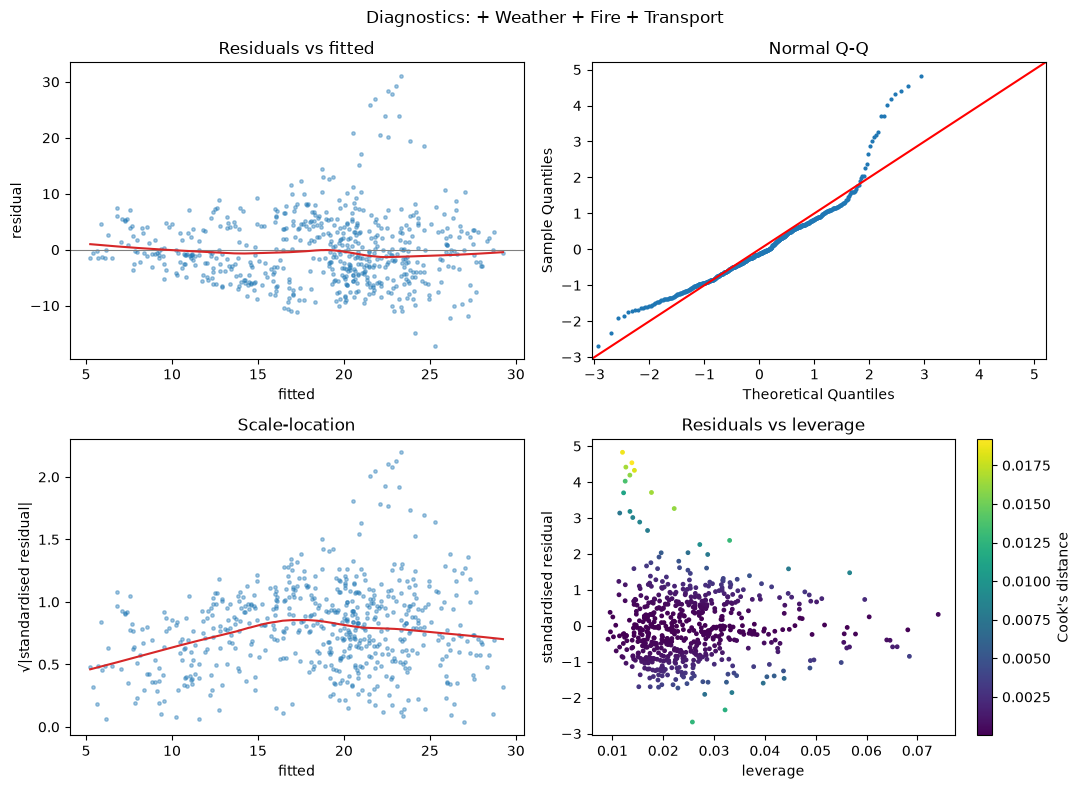

In [52]:
infl = model_full.get_influence()
fitted, resid = model_full.fittedvalues, model_full.resid
std_resid = infl.resid_studentized_internal
lev, cooks = infl.hat_matrix_diag, infl.cooks_distance[0]
low = sm.nonparametric.lowess

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0, 0].scatter(fitted, resid, s=6, alpha=0.4); ax[0, 0].axhline(0, c="grey", lw=0.8)
ax[0, 0].plot(*low(resid, fitted).T, c="tab:red"); ax[0, 0].set(title="Residuals vs fitted", xlabel="fitted", ylabel="residual")
sm.qqplot(std_resid, line="45", ax=ax[0, 1], markersize=2); ax[0, 1].set_title("Normal Q-Q")
ax[1, 0].scatter(fitted, np.sqrt(np.abs(std_resid)), s=6, alpha=0.4)
ax[1, 0].plot(*low(np.sqrt(np.abs(std_resid)), fitted).T, c="tab:red"); ax[1, 0].set(title="Scale-location", xlabel="fitted", ylabel="√|standardised residual|")
sc = ax[1, 1].scatter(lev, std_resid, s=6, c=cooks, cmap="viridis"); plt.colorbar(sc, ax=ax[1, 1], label="Cook's distance")
ax[1, 1].set(title="Residuals vs leverage", xlabel="leverage", ylabel="standardised residual")
plt.suptitle(f"Diagnostics: {FULL}"); plt.tight_layout()
fig.savefig(FIG / "diagnostics.png", dpi=150, bbox_inches="tight"); plt.show()

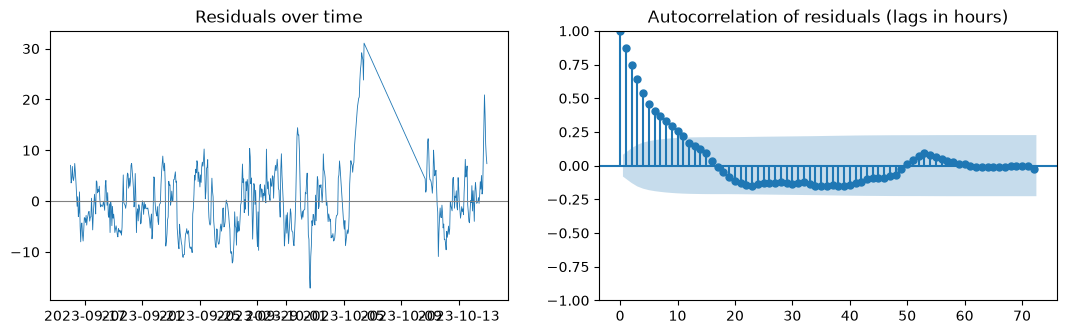

In [53]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(resid.index, resid, lw=0.6); ax[0].axhline(0, c="grey", lw=0.8); ax[0].set_title("Residuals over time")
plot_acf(resid, lags=72, ax=ax[1]); ax[1].set_title("Autocorrelation of residuals (lags in hours)")
plt.show()

What each plot checks:
- **Residuals vs fitted:** a curve in the red line means the linear form misses something (the lecture's "points to ponder": a high R² does not make the model adequate).
- **Q-Q:** heavy tails mean the normal-based intervals in §9 may be too narrow for extreme hours.
- **Scale-location:** a rising line means the spread grows with the level (heteroscedasticity), which is common for pollution.
- **Leverage:** points with large Cook's distance have outsized influence on the fit.
- **ACF:** large spikes at short lags confirm the errors are not independent, which is why the HAC errors above and a time-based validation are needed.

None of the plots proves an assumption holds. They only show where it visibly fails.

# 8. Validation inside the training period (rolling origin)

To choose between models without touching the test set, each day from 1 to 14 Oct is predicted using only rows whose **target** is before that day starts. The models are refitted every day, as a real daily forecasting service would be. This period includes the early-October haze build-up.

Two naive baselines are included:
- **Persistence:** predict tomorrow = today, ŷ = PM2.5 at t.
- **Hourly climatology:** predict the training-period average for that hour of day.

In [54]:
def ols_predictor(formula):
    return lambda fit_rows, new: smf.ols(formula, data=fit_rows).fit().predict(new)

def persistence(fit_rows, new):
    return new["pm25_lag0"]

def climatology(fit_rows, new):
    by_hour = fit_rows.groupby(fit_rows["target_time"].dt.hour)["y"].mean()
    return pd.Series(new["target_time"].dt.hour.map(by_hour).to_numpy(), index=new.index)

predictors = {"Persistence": persistence, "Hourly climatology": climatology}
predictors.update({name: ols_predictor(f) for name, f in formulas.items()})

def rolling_origin(data, days):
    out = []
    for day in days:
        fit_rows = data[data["target_time"] < day]
        new = data[(data.index >= day) & (data.index < day + pd.Timedelta(days=1))]
        if len(new) == 0:
            continue
        preds = pd.DataFrame({name: f(fit_rows, new) for name, f in predictors.items()})
        preds.insert(0, "y", new["y"]); preds.insert(0, "day", day)
        out.append(preds)
    return pd.concat(out)

val_days = pd.date_range("2023-10-01", "2023-10-14", freq="D", tz=SGT)
val = rolling_origin(train, val_days)
print(f"{len(val)} validation forecasts over {val['day'].nunique()} days")

227 validation forecasts over 11 days


In [55]:
def scores(df, names):
    sse_persist = np.sum((df["y"] - df["Persistence"]) ** 2)
    rows = {}
    for name in names:
        err = df["y"] - df[name]
        daily_rmse = err.pow(2).groupby(df["day"]).mean().pow(0.5)
        rows[name] = {"RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
                      "skill_vs_persistence": 1 - np.sum(err ** 2) / sse_persist,
                      "daily_RMSE_sd": daily_rmse.std(), "daily_RMSE_max": daily_rmse.max()}
    return pd.DataFrame(rows).T

validation_scores = scores(val, predictors)
validation_scores.round(3)

,RMSE,MAE,skill_vs_persistence,daily_RMSE_sd,daily_RMSE_max
Persistence,10.649,7.727,0.000,7.595,32.447
Hourly climatology,9.555,6.337,0.195,7.912,31.481
Season only,9.821,6.691,0.149,7.841,31.268
Baseline (persistence + season),9.960,7.045,0.125,7.754,31.765
+ Weather,10.050,7.253,0.109,7.618,31.321
+ Weather + Fire,8.970,6.297,0.290,6.533,27.312
+ Weather + Fire + Transport,9.030,6.374,0.281,6.515,27.334


`daily_RMSE_sd` shows how much the error varies from day to day: the variability of performance the rubric asks for. Skill below 0 means the model did worse than simply repeating today's value.

## Variable selection: which variables, and from which data source?

The model ladder above adds whole data sources in a fixed order. Here the question is asked **one variable at a time**: among the variables the three data sources provide, which ones actually improve out-of-sample forecasts, and does the best set need all sources or just one?

- **Always kept:** the calendar terms `hour_sin`, `hour_cos` and `is_weekend`. They come from the clock, not from a data source, and they define the season baseline.
- **Candidates:** the other variables of the full model. Each one is tagged with the data source it comes from (table below).
- **Rules:** every choice is made on the training period, with the same rolling-origin folds (1–14 Oct). The final test is used once, in section 9, where the selected model is scored alongside the ladder.

### Subset-selection methods available

**A. Search strategies: which subsets to try**

| method | how it works | models fitted (p candidates) | notes |
|---|---|---|---|
| **Best subset (exhaustive)** | fit every combination; keep the best model of each size | 2^p | exact; feasible here (p = 11 → 2,048 models) |
| Leaps-and-bounds / branch-and-bound | best subset that skips subsets which cannot win | far fewer than 2^p | same answer as best subset, only faster; not needed at this size |
| **Forward stepwise** | start empty, add the variable that improves the fit most, repeat | about p²/2 | greedy: can miss the best subset |
| **Backward stepwise** | start full, remove the least useful variable, repeat | about p²/2 | needs n > p (here n ≈ 590) |
| Hybrid (bidirectional) stepwise | forward steps that may also drop a variable added earlier | about p² | between forward and backward |
| Forward stagewise | many tiny coefficient updates | many small steps | close to the lasso path; mainly of theoretical interest |

**B. Criteria: how to pick the winner or the model size**

| criterion | type | use |
|---|---|---|
| RSS / R² (linear), log-likelihood (logistic) | in-sample | only to compare models **of the same size**; always prefers bigger models |
| Mallows' Cp, AIC, BIC, adjusted R² | in-sample, penalised | BIC penalises most, so it picks smaller models |
| Validation set / cross-validation | out-of-sample | the fairest; for time series it must be **time-ordered** (rolling origin), never random k-fold |

**C. Shrinkage methods that also select**

| method | what it does |
|---|---|
| **Lasso** | an L1 penalty sets some coefficients exactly to zero |
| Elastic net | lasso + ridge; keeps groups of correlated variables together |
| Adaptive lasso | lasso with per-variable weights; less biased |
| Relaxed lasso | lasso chooses the variables, then an unpenalised refit |
| Group lasso | keeps or drops whole groups (e.g. all variables of one source) |
| LARS | an algorithm that computes the whole lasso path cheaply |

**D. Supporting techniques**

- **Stability selection:** repeat the selection over many folds or resamples and count how often each variable is kept.
- **Screening** (e.g. sure independence screening): drop clearly useless variables first; only needed when p is very large.
- Not selection methods: ridge regression keeps every variable; PCR and PLS build combinations of variables instead of choosing among them.

### Why we use best subset + forward/backward + lasso + stability counts

1. **Best subset is the main method.** With p = 11 every subset can be fitted, so there is no reason to accept an approximation. For each size, the best model is the one with the smallest training RSS (linear) or highest log-likelihood (logistic). Comparing models of the *same* size this way is fair.
2. **The size is chosen by time-ordered cross-validation**, using the same rolling-origin folds as the ladder (RMSE for linear, Brier score for logistic). Training fit always improves as variables are added, so it cannot choose the size. Random k-fold would mix future and past hours, which leaks information through the strong hour-to-hour autocorrelation. BIC is shown next to the CV curve as an in-sample cross-check.
3. **Forward and backward stepwise are run for comparison.** They are the greedy shortcuts used when best subset is too expensive. If they reach the same variables, the result does not depend on the search method. If they disagree, that shows the selection is fragile.
4. **Lasso is the shrinkage counterpart.** It selects by penalising coefficients instead of searching subsets, and treats correlated inputs differently (it tends to keep one of a correlated pair and shrink the other). Candidates are standardised inside each fold, using that fold's training rows only, so the penalty treats every variable on the same scale. The calendar terms are not penalised. The penalty is chosen by the same rolling-origin CV.
5. **Stability counts** rerun forward stepwise (at the chosen size) and the lasso (at the chosen penalty) in each rolling-origin fold (one per validation day with data, 11 here) and record how often each variable is kept. A variable kept in nearly every fold is a robust finding; one kept in half the folds is not.
6. **The test period is not touched** by any of this. The best-subset model is handed to the final-test section and scored once.

**Caveats to state in the report**

- **p-values of a selected model are not valid.** Selecting variables and then testing them on the same data makes them look more significant than they are. Formal evidence for the fire terms stays with the pre-specified nested tests (F / likelihood-ratio and HAC Wald) earlier in the notebook. Selection is used here to *describe* which variables help forecasts.
- **Correlated variables can swap.** Temperature and humidity move together, and so do the two fire sectors and fire vs. transport. "Not selected" does not mean "no effect"; it can mean "already covered by a correlated variable".
- **One haze episode.** Most of the fire signal comes from early October 2023, so the selection can change with more haze seasons.

In [56]:
import warnings
from itertools import combinations

LOGIT = False
RESP = formulas[FULL].split("~")[0].strip()          # "y" (linear) or "high" (logistic)
SEASON_TERMS = [t.strip() for t in season.split("+")]
CANDIDATES = [t.strip() for t in formulas[FULL].split("~")[1].split("+") if t.strip() not in SEASON_TERMS]

def source_of(v):
    if v.startswith("pm25"): return "PM2.5 (NEA, data.gov.sg)"
    if v.startswith("frp_"): return "Fires (NASA FIRMS)"
    if v.startswith("transport_"): return "Fires × Weather"
    return "Weather (data.gov.sg)"

SOURCE = {v: source_of(v) for v in CANDIDATES}
SOURCES = list(dict.fromkeys(SOURCE.values()))
COLOR = {"PM2.5 (NEA, data.gov.sg)": "#4C72B0", "Weather (data.gov.sg)": "#55A868",
         "Fires (NASA FIRMS)": "#C44E52", "Fires × Weather": "#DD8452"}
LIGHT = {"PM2.5 (NEA, data.gov.sg)": "#dbe4f2", "Weather (data.gov.sg)": "#dcefe0",
         "Fires (NASA FIRMS)": "#f4dada", "Fires × Weather": "#f8e6d6"}
p = len(CANDIDATES)
print(f"{p} candidates -> {2 ** p:,} subsets; always kept: {SEASON_TERMS}")
pd.DataFrame({"data source": SOURCE}).rename_axis("variable")

11 candidates -> 2,048 subsets; always kept: ['hour_sin', 'hour_cos', 'is_weekend']


,data source
variable,
pm25_lag0,"PM2.5 (NEA, data.gov.sg)"
pm25_lag24,"PM2.5 (NEA, data.gov.sg)"
temp,Weather (data.gov.sg)
rh,Weather (data.gov.sg)
rain_24h,Weather (data.gov.sg)
u,Weather (data.gov.sg)
v,Weather (data.gov.sg)
frp_E_24h,Fires (NASA FIRMS)
frp_S_24h,Fires (NASA FIRMS)


### Best subset, forward and backward stepwise

For every size k = 0 … p, each search keeps the model with the best training fit. That is the lowest RSS for linear, or the highest log-likelihood for logistic. Size 0 is the calendar-only model and size p is the full model, so both ends must reproduce models already fitted in the ladder; this is checked below.

In [57]:
def arrays(rows):
    return (rows[RESP].to_numpy(float), sm.add_constant(rows[SEASON_TERMS].to_numpy(float), has_constant="add"),
            rows[CANDIDATES].to_numpy(float))

def fit_score(cols, data):
    """Training loss (RSS, or minus the log-likelihood) of calendar + the candidate columns `cols`."""
    y, Xcal, Xc = data
    X = np.column_stack([Xcal, Xc[:, list(cols)]]) if cols else Xcal
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        try:
            r = sm.Logit(y, X).fit(disp=0, maxiter=200) if LOGIT else sm.OLS(y, X).fit()
        except Exception:                      # e.g. perfect separation in a logistic fit
            return np.inf, None
    return (-r.llf if LOGIT else r.ssr), r

def stepwise(data, forward=True):
    cur = [] if forward else list(range(p))
    path = {len(cur): tuple(cur)}
    while (len(cur) < p) if forward else cur:
        options = [j for j in range(p) if j not in cur] if forward else cur
        trials = [(fit_score(sorted(cur + [j]) if forward else [c for c in cur if c != j], data)[0], j) for j in options]
        j = min(trials)[1]
        cur = sorted(cur + [j]) if forward else [c for c in cur if c != j]
        path[len(cur)] = tuple(cur)
    return path

train_arrays = arrays(train)
best = {}
for k in range(p + 1):
    for cols in combinations(range(p), k):
        s, r = fit_score(cols, train_arrays)
        if k not in best or s < best[k][0]:
            best[k] = (s, cols, r)
paths = {"Best subset": {k: best[k][1] for k in best},
         "Forward": stepwise(train_arrays, True),
         "Backward": stepwise(train_arrays, False)}

# self-checks: both ends equal models already in the ladder, and the greedy paths share those ends
fit = (lambda f: smf.logit(f, train).fit(disp=0, maxiter=200)) if LOGIT else (lambda f: smf.ols(f, train).fit())
loss = (lambda r: -r.llf) if LOGIT else (lambda r: r.ssr)
assert np.isclose(best[p][0], loss(fit(formulas[FULL]))), "full-size subset differs from the full model"
assert np.isclose(best[0][0], loss(fit(formulas["Season only"]))), "size-0 subset differs from 'Season only'"
assert all(pth[0] == () and pth[p] == tuple(range(p)) for pth in paths.values())

names = lambda cols: ", ".join(CANDIDATES[j] for j in cols) or "(calendar only)"
in_sample = pd.DataFrame({k: {"best subset": names(best[k][1]),
                              ("McFadden R²" if LOGIT else "adj R²"): best[k][2].prsquared if LOGIT else best[k][2].rsquared_adj,
                              "AIC": best[k][2].aic, "BIC": best[k][2].bic} for k in best}).T.rename_axis("size")
in_sample

,best subset,adj R²,AIC,BIC
size,,,,
0,(calendar only),0.000234,4163.873608,4181.373708
1,frp_S_24h,0.262421,3986.331395,4008.206519
2,"frp_E_24h, frp_S_24h",0.344388,3918.170662,3944.420811
3,"pm25_lag24, frp_E_24h, frp_S_24h",0.378172,3888.104319,3918.729493
4,"pm25_lag24, frp_E_24h, frp_S_24h, transport_S",0.386302,3881.365584,3916.365782
5,"pm25_lag24, temp, rh, frp_E_24h, frp_S_24h",0.391152,3877.693971,3917.069194
6,"pm25_lag24, temp, rh, frp_E_24h, frp_S_24h, tr...",0.397751,3872.28039,3916.030638
7,"pm25_lag0, pm25_lag24, temp, rh, frp_E_24h, fr...",0.40282,3868.300239,3916.425512
8,"pm25_lag0, pm25_lag24, temp, rh, rain_24h, frp...",0.40239,3869.703479,3922.203777


### Choosing the size by rolling-origin cross-validation

Each model on each path is refitted every validation day, using only rows whose target comes before that day, exactly as in the ladder comparison. The chosen size is the one with the lowest validation error on the best-subset path.

In [58]:
make = logit_predictor if LOGIT else ols_predictor
formula_of = lambda cols: f"{RESP} ~ " + " + ".join(SEASON_TERMS + [CANDIDATES[j] for j in cols])
METRIC = "Brier" if LOGIT else "RMSE"

def folds(rows=train):
    for day in val_days:
        new = rows[(rows.index >= day) & (rows.index < day + pd.Timedelta(days=1))]
        if len(new):
            yield rows[rows["target_time"] < day], new

def summarise(err):
    e = pd.concat(err)
    return float((e ** 2).mean()) if LOGIT else float(np.sqrt((e ** 2).mean()))

_cv = {}
def cv_error(cols):
    cols = tuple(sorted(cols))
    if cols not in _cv:
        f = make(formula_of(cols))
        _cv[cols] = summarise([new[RESP] - f(fit_rows, new) for fit_rows, new in folds()])
    return _cv[cols]

cv_table = pd.DataFrame({name: {k: cv_error(cols) for k, cols in pth.items()} for name, pth in paths.items()}).rename_axis("size")
K_BEST = int(cv_table["Best subset"].idxmin())
K_PATH = {name: int(cv_table[name].idxmin()) for name in paths}
print(f"validation {METRIC} by size; chosen size (best subset) = {K_BEST}: {names(best[K_BEST][1])}")
print(f"forward picks size {K_PATH['Forward']}: {names(paths['Forward'][K_PATH['Forward']])}")
print(f"backward picks size {K_PATH['Backward']}: {names(paths['Backward'][K_PATH['Backward']])}")
cv_table.assign(BIC=in_sample["BIC"].astype(float)).round(4)

validation RMSE by size; chosen size (best subset) = 3: pm25_lag24, frp_E_24h, frp_S_24h
forward picks size 3: pm25_lag24, frp_E_24h, frp_S_24h
backward picks size 3: pm25_lag24, frp_E_24h, frp_S_24h


,Best subset,Forward,Backward,BIC
size,,,,
0,9.8212,9.8212,9.8212,4181.3737
1,9.0909,9.0909,9.0909,4008.2065
2,8.8747,8.8747,8.8747,3944.4208
3,8.7209,8.7209,8.7209,3918.7295
4,8.7391,8.7391,8.8359,3916.3658
5,8.8776,8.8080,8.8776,3917.0692
6,8.8460,8.8460,8.8460,3916.0306
7,8.8758,8.8758,8.8758,3916.4255
8,8.9183,8.9183,8.9372,3922.2038


### Lasso

The candidates are standardised inside every fold with that fold's own training mean and standard deviation, so no information from the predicted day leaks into the scaling. The calendar terms and the intercept are not penalised. The penalty α is chosen by the same rolling-origin CV, then the lasso is refitted on the whole training period at that α to read off which variables survive.

In [59]:
ALPHAS = np.logspace(-4, -0.5, 20) if LOGIT else np.logspace(-3, 0.7, 20)

def lasso_fit(rows, alpha):
    mu, sd = rows[CANDIDATES].mean(), rows[CANDIDATES].std()
    X = sm.add_constant(pd.concat([rows[SEASON_TERMS], (rows[CANDIDATES] - mu) / sd], axis=1), has_constant="add").astype(float)
    pen = np.r_[np.zeros(1 + len(SEASON_TERMS)), np.full(p, alpha)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if LOGIT:   # Logit's L1 objective is a sum over rows, OLS's is a mean, so scale α by n to match
            r = sm.Logit(rows[RESP].astype(float), X).fit_regularized(method="l1", alpha=pen * len(rows), disp=0)
        else:
            r = sm.OLS(rows[RESP].astype(float), X).fit_regularized(method="elastic_net", L1_wt=1.0, alpha=pen, maxiter=1000)  # default 50 does not converge
    return pd.Series(np.asarray(r.params), index=X.columns), mu, sd

def lasso_predict(params, mu, sd, new):
    X = sm.add_constant(pd.concat([new[SEASON_TERMS], (new[CANDIDATES] - mu) / sd], axis=1), has_constant="add").astype(float)
    eta = X.to_numpy() @ params.to_numpy()
    return pd.Series(1 / (1 + np.exp(-eta)) if LOGIT else eta, index=new.index)

if not LOGIT:   # self-check: with α = 0 the lasso is ordinary least squares
    par, mu, sd = lasso_fit(train, 0.0)
    assert np.allclose(lasso_predict(par, mu, sd, train), smf.ols(formulas[FULL], train).fit().fittedvalues, atol=1e-2)

lasso_cv = pd.Series({a: summarise([new[RESP] - lasso_predict(*lasso_fit(fit_rows, a), new) for fit_rows, new in folds()])
                      for a in ALPHAS}, name=f"validation {METRIC}")
ALPHA = float(lasso_cv.idxmin())
lasso_path = pd.DataFrame({a: lasso_fit(train, a)[0][CANDIDATES] for a in ALPHAS}).T
lasso_kept = lasso_path.loc[ALPHA].abs() > 1e-8
print(f"chosen α = {ALPHA:.4g} (validation {METRIC} {lasso_cv.min():.4f}); "
      f"kept {int(lasso_kept.sum())} of {p}: {', '.join(lasso_kept.index[lasso_kept])}")
lasso_cv.round(4).to_frame().T

chosen α = 0.5325 (validation RMSE 8.7845); kept 3 of 11: pm25_lag24, frp_E_24h, frp_S_24h


,0.001000,0.001566,0.002452,0.003839,0.006011,0.009412,0.014737,0.023076,0.036132,0.056576,0.088587,0.138709,0.217191,0.340078,0.532495,0.833782,1.305538,2.044214,3.200834,5.011872
validation RMSE,9.0208,9.0413,8.9989,9.0342,9.0358,9.0237,8.9564,9.0105,8.9265,9.0454,9.0522,8.9766,8.9347,8.7949,8.7845,8.8439,8.9697,9.2013,9.5404,9.8212


### Stability across the rolling-origin folds

The selection is repeated on each fold's training rows: forward stepwise stopped at the size chosen above, and the lasso at the chosen α. The table counts how often each variable is kept.

In [60]:
fold_list = list(folds())
stab_fwd = pd.Series(0, index=CANDIDATES); stab_lasso = pd.Series(0, index=CANDIDATES)
for fit_rows, _ in fold_list:
    for j in stepwise(arrays(fit_rows), True)[K_PATH["Forward"]]:
        stab_fwd[CANDIDATES[j]] += 1
    stab_lasso += (lasso_fit(fit_rows, ALPHA)[0][CANDIDATES].abs() > 1e-8).astype(int)
stability = pd.DataFrame({"forward, % of folds": 100 * stab_fwd / len(fold_list),
                          "lasso, % of folds": 100 * stab_lasso / len(fold_list)})
print(f"{len(fold_list)} folds")

11 folds


### Summary: selected variables by data source (report table)

Each row is one candidate variable, coloured by its data source. ✓ means the method keeps the variable at its CV-chosen size or penalty.

The second table answers the source-level question with the same CV folds:
- **only this source:** the calendar plus every variable of that one source;
- **all sources:** the full model;
- **selected:** the best-subset model;
- **+ error if removed:** how much the selected model's validation error rises if that source's variables are taken out. A positive value means the source is needed.

In [61]:
kept = lambda cols: [j in cols for j in range(p)]
sel = pd.DataFrame({"data source": [SOURCE[v] for v in CANDIDATES],
                    "best subset": kept(best[K_BEST][1]),
                    "forward": kept(paths["Forward"][K_PATH["Forward"]]),
                    "backward": kept(paths["Backward"][K_PATH["Backward"]]),
                    "lasso": lasso_kept.to_numpy()}, index=pd.Index(CANDIDATES, name="variable")).join(stability.round(0))
sel = sel.sort_values("data source", key=lambda s: s.map(SOURCES.index), kind="stable")

chosen = best[K_BEST][1]
src_rows = {}
for s in SOURCES:
    own = [j for j in range(p) if SOURCE[CANDIDATES[j]] == s]
    rest = [j for j in chosen if j not in own]
    src_rows[s] = {"variables available": len(own), "kept by best subset": sum(j in chosen for j in own),
                   "kept by lasso": int(lasso_kept.iloc[own].sum()),
                   f"CV {METRIC}, only this source": cv_error(own),
                   f"+ {METRIC} if removed from selected": cv_error(rest) - cv_error(chosen) if len(rest) < len(chosen) else 0.0}
by_source = pd.DataFrame(src_rows).T.rename_axis("data source")
COUNTS = ["variables available", "kept by best subset", "kept by lasso"]
by_source[COUNTS] = by_source[COUNTS].astype(int)
print(f"validation {METRIC}: calendar only {cv_error(()):.4f} | all sources {cv_error(range(p)):.4f} | "
      f"selected ({K_BEST} variables) {cv_error(chosen):.4f}")
print(sel.replace({True: "✓", False: ""}).to_string()); print(); print(by_source.round(4).to_string())

shade = lambda row: [f"background-color: {LIGHT[row['data source']]}"] * len(row)
display(sel.replace({True: "✓", False: ""}).style.apply(shade, axis=1).format(precision=0)
           .set_caption("Selected variables, coloured by data source"))
display(by_source.style.apply(lambda r: [f"background-color: {LIGHT[r.name]}"] * len(r), axis=1).format(precision=4)
           .set_caption("By data source (validation folds 1–14 Oct)"))

validation RMSE: calendar only 9.8212 | all sources 9.0301 | selected (3 variables) 8.7209
                          data source best subset forward backward lasso  forward, % of folds  lasso, % of folds
variable                                                                                                        
pm25_lag0    PM2.5 (NEA, data.gov.sg)                                                     0.0                0.0
pm25_lag24   PM2.5 (NEA, data.gov.sg)           ✓       ✓        ✓     ✓                 91.0              100.0
temp            Weather (data.gov.sg)                                                     0.0                0.0
rh              Weather (data.gov.sg)                                                     0.0                0.0
rain_24h        Weather (data.gov.sg)                                                     9.0                0.0
u               Weather (data.gov.sg)                                                     0.0                0.0
v    

,data source,best subset,forward,backward,lasso,"forward, % of folds","lasso, % of folds"
variable,,,,,,,
pm25_lag0,"PM2.5 (NEA, data.gov.sg)",,,,,0,0
pm25_lag24,"PM2.5 (NEA, data.gov.sg)",✓,✓,✓,✓,91,100
temp,Weather (data.gov.sg),,,,,0,0
rh,Weather (data.gov.sg),,,,,0,0
rain_24h,Weather (data.gov.sg),,,,,9,0
u,Weather (data.gov.sg),,,,,0,0
v,Weather (data.gov.sg),,,,,0,0
frp_E_24h,Fires (NASA FIRMS),✓,✓,✓,✓,100,100
frp_S_24h,Fires (NASA FIRMS),✓,✓,✓,✓,100,100


,variables available,kept by best subset,kept by lasso,"CV RMSE, only this source",+ RMSE if removed from selected
data source,,,,,
"PM2.5 (NEA, data.gov.sg)",2,1,1,9.9599,0.1538
Weather (data.gov.sg),5,0,0,9.6125,0.0000
Fires (NASA FIRMS),2,2,2,8.8747,1.1679
Fires × Weather,2,0,0,9.8268,0.0000


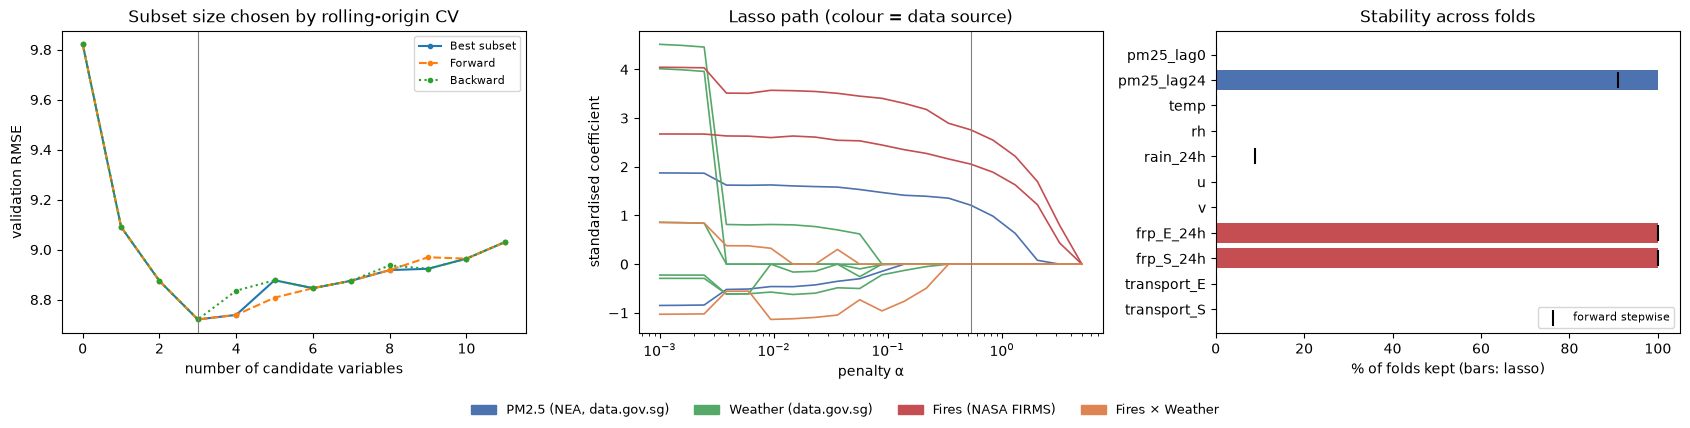

In [62]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for name, ls in zip(paths, ["-", "--", ":"]):
    ax[0].plot(cv_table.index, cv_table[name], ls, marker="o", ms=3, label=name)
ax[0].axvline(K_BEST, color="grey", lw=0.8)
ax[0].set(xlabel="number of candidate variables", ylabel=f"validation {METRIC}", title="Subset size chosen by rolling-origin CV")
ax[0].legend(fontsize=8)
for v in CANDIDATES:
    ax[1].plot(lasso_path.index, lasso_path[v], color=COLOR[SOURCE[v]], lw=1.2)
ax[1].axvline(ALPHA, color="grey", lw=0.8)
ax[1].set(xscale="log", xlabel="penalty α", ylabel="standardised coefficient", title="Lasso path (colour = data source)")
order = sel.index[::-1]
ax[2].barh(order, sel.loc[order, "lasso, % of folds"], color=[COLOR[SOURCE[v]] for v in order])
ax[2].scatter(sel.loc[order, "forward, % of folds"], order, marker="|", s=120, c="k", label="forward stepwise")
ax[2].set(xlim=(0, 105), xlabel="% of folds kept (bars: lasso)", title="Stability across folds"); ax[2].legend(fontsize=8, loc="lower right")
handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR[s]) for s in SOURCES]
fig.legend(handles, SOURCES, loc="lower center", ncol=len(SOURCES), fontsize=9, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); fig.savefig(FIG / "linear_selection.png", dpi=150, bbox_inches="tight"); plt.show()

### Hand-off to the final test

The best-subset model at the CV-chosen size is added to the list of models, so the final-test section below scores it once, together with the ladder. This is the only time its test performance is looked at.

In [63]:
SELECTED = "Best subset (CV)"
formulas[SELECTED] = formula_of(best[K_BEST][1])
predictors[SELECTED] = make(formulas[SELECTED])
print(f"{SELECTED}: {formulas[SELECTED]}")

Best subset (CV): y ~ hour_sin + hour_cos + is_weekend + pm25_lag24 + frp_E_24h + frp_S_24h


# 9. Prediction and out-of-sample evaluation (final test, used once)

All models are refitted on the full training period and scored once on 16–30 Oct forecasts.

In [64]:
test_pred = pd.DataFrame({name: f(train, test) for name, f in predictors.items()}, index=test.index)
test_pred.insert(0, "y", test["y"]); test_pred.insert(0, "day", test.index.floor("D"))

# the persistence baseline computed by hand, as a check on the table below
assert np.isclose(np.sqrt(np.mean((test["y"] - test["pm25_lag0"]) ** 2)),
                  np.sqrt(np.mean((test_pred["y"] - test_pred["Persistence"]) ** 2)))

## Confidence vs prediction intervals

In [65]:
frame = model_full.get_prediction(test).summary_frame(alpha=0.05)
intervals = pd.DataFrame({
    "actual": test["y"], "fit": frame["mean"],
    "mean_lower": frame["mean_ci_lower"], "mean_upper": frame["mean_ci_upper"],
    "prediction_lower": frame["obs_ci_lower"], "prediction_upper": frame["obs_ci_upper"]})
inside = (intervals["actual"] >= intervals["prediction_lower"]) & (intervals["actual"] <= intervals["prediction_upper"])
print(f"95% prediction interval: average width {np.mean(intervals['prediction_upper'] - intervals['prediction_lower']):.1f} µg/m³, "
      f"covers {inside.mean():.0%} of test hours")
intervals.iloc[::24].round(1)

95% prediction interval: average width 26.0 µg/m³, covers 90% of test hours


,actual,fit,mean_lower,mean_upper,prediction_lower,prediction_upper
timestamp,,,,,,
2023-10-16 00:00:00+08:00,25.0,16.5,14.9,18.1,3.7,29.3
2023-10-17 00:00:00+08:00,19.8,27.2,25.1,29.2,14.3,40.1
2023-10-19 01:00:00+08:00,10.6,22.2,19.5,24.9,9.2,35.2
2023-10-20 01:00:00+08:00,9.6,10.4,8.1,12.7,-2.6,23.3
2023-10-21 01:00:00+08:00,18.8,1.7,-0.6,3.9,-11.3,14.6
2023-10-22 01:00:00+08:00,18.8,4.7,1.3,8.0,-8.5,17.8
2023-10-23 01:00:00+08:00,13.2,9.2,6.9,11.4,-3.7,22.1
2023-10-24 01:00:00+08:00,13.2,11.3,9.0,13.5,-1.6,24.2
2023-10-25 01:00:00+08:00,17.6,10.8,7.7,13.8,-2.3,23.8


The **confidence interval** is for the *average* PM2.5 at given inputs, so it is narrow. The **prediction interval** is for *one* future hour and adds the irreducible noise σ², so it is wide. For a next-day advisory the prediction interval is the honest statement (the lecture's "points to ponder", question 3). The coverage above is measured on the test data, not assumed. If it falls well short of 95%, the independent-normal-error assumption is failing out of sample.

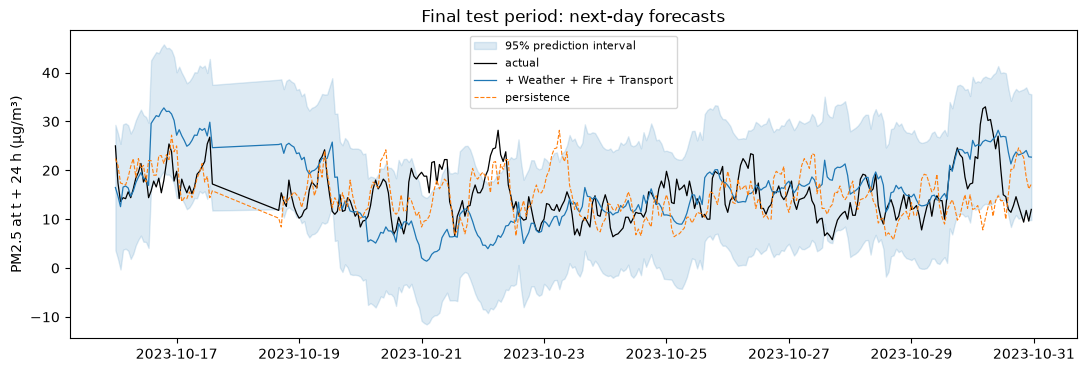

In [66]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(intervals.index, intervals["prediction_lower"], intervals["prediction_upper"], color="tab:blue", alpha=0.15, label="95% prediction interval")
ax.plot(intervals.index, intervals["actual"], c="black", lw=0.9, label="actual")
ax.plot(intervals.index, intervals["fit"], c="tab:blue", lw=0.9, label=FULL)
ax.plot(test_pred.index, test_pred["Persistence"], c="tab:orange", lw=0.8, ls="--", label="persistence")
ax.set(ylabel="PM2.5 at t + 24 h (µg/m³)", title="Final test period: next-day forecasts"); ax.legend(fontsize=8)
fig.savefig(FIG / "test_forecasts.png", dpi=150, bbox_inches="tight"); plt.show()

## Compare models on the test period

The course helper below is unchanged. The difference is the `baseline` argument. The wine example used the **training** mean because its test set had only two prices, so a test-set mean would have been unstable. Here the test set has hundreds of hours, so the standard out-of-sample R² with the **test** mean ȳ_test is used. The training-mean version is shown alongside for comparison only. It comes out higher whenever the test period's average differs from the training average, because part of the "explained" variation is just that level shift.

In [67]:
def predictive_r_squared(actual, predicted, baseline):
    return 1 - np.sum((actual - predicted) ** 2) / np.sum((actual - baseline) ** 2)

test_scores = scores(test_pred, predictors)
test_scores["R2_test_mean"] = [predictive_r_squared(test_pred["y"], test_pred[n], test_pred["y"].mean()) for n in predictors]
test_scores["R2_train_mean"] = [predictive_r_squared(test_pred["y"], test_pred[n], train["y"].mean()) for n in predictors]
print(f"test mean of y = {test_pred['y'].mean():.2f}, training mean of y = {train['y'].mean():.2f} µg/m³")
test_scores.round(3)

test mean of y = 15.01, training mean of y = 18.57 µg/m³


,RMSE,MAE,skill_vs_persistence,daily_RMSE_sd,daily_RMSE_max,R2_test_mean,R2_train_mean
Persistence,5.817,4.543,0.000,2.301,12.428,-0.384,0.089
Hourly climatology,6.055,5.127,-0.083,1.666,8.335,-0.500,0.013
Season only,6.220,5.296,-0.143,1.672,8.255,-0.582,-0.041
Baseline (persistence + season),5.500,4.542,0.106,1.737,8.988,-0.237,0.186
+ Weather,5.322,4.394,0.163,1.566,8.855,-0.158,0.238
+ Weather + Fire,7.260,5.575,-0.558,2.823,11.505,-1.156,-0.419
+ Weather + Fire + Transport,7.407,5.598,-0.621,3.036,11.713,-1.244,-0.477
Best subset (CV),6.389,4.932,-0.206,2.542,10.305,-0.669,-0.099


## Uncertainty of the improvement over persistence

In [68]:
rng = np.random.default_rng(42)
days = test_pred["day"].unique()
sq = {name: (test_pred["y"] - test_pred[name]) ** 2 for name in predictors}

def boot_rmse_diff(name, B=2000):
    # resample whole days (blocks) so the within-day correlation is kept
    by_day = {d: test_pred.index[test_pred["day"] == d] for d in days}
    diffs = []
    for _ in range(B):
        idx = np.concatenate([by_day[d] for d in rng.choice(days, size=len(days), replace=True)])
        diffs.append(np.sqrt(sq[name].loc[idx].mean()) - np.sqrt(sq["Persistence"].loc[idx].mean()))
    return np.percentile(diffs, [2.5, 50, 97.5])

boot = pd.DataFrame({n: boot_rmse_diff(n) for n in formulas}, index=["2.5%", "median", "97.5%"]).T
boot.columns.name = "RMSE(model) − RMSE(persistence), µg/m³"
boot.round(2)

"RMSE(model) − RMSE(persistence), µg/m³",2.5%,median,97.5%
Season only,-0.86,0.45,1.70
Baseline (persistence + season),-1.32,-0.30,0.70
+ Weather,-1.42,-0.46,0.44
+ Weather + Fire,-0.56,1.52,3.41
+ Weather + Fire + Transport,-0.48,1.64,3.71
Best subset (CV),-1.33,0.57,2.40


A negative interval that excludes 0 means the model is reliably better than persistence on this test period. An interval that includes 0 means the improvement (or deterioration) is within day-to-day noise.

## Sensitivity: log-scale target

In [69]:
log_formula = formulas[FULL].replace("y ~", "np.log(y) ~", 1)
model_log = smf.ols(log_formula, data=train).fit()
pred_log = np.exp(model_log.predict(test))          # exp of the mean log is the conditional median
err = test["y"] - pred_log
print(f"{FULL}, fitted on log PM2.5: test RMSE {np.sqrt(np.mean(err ** 2)):.3f}, MAE {np.mean(np.abs(err)):.3f} µg/m³ "
      f"(raw-scale model: RMSE {test_scores.loc[FULL, 'RMSE']:.3f})")

+ Weather + Fire + Transport, fitted on log PM2.5: test RMSE 6.843, MAE 5.089 µg/m³ (raw-scale model: RMSE 7.407)


## Largest test errors (failure cases)

In [70]:
worst = test_pred.assign(error=test_pred["y"] - test_pred[FULL], persistence_error=test_pred["y"] - test_pred["Persistence"])
worst = worst.reindex(worst["error"].abs().sort_values(ascending=False).index)
worst[["y", FULL, "Persistence", "error", "persistence_error"]].head(10).round(1)

,y,+ Weather + Fire + Transport,Persistence,error,persistence_error
timestamp,,,,,
2023-10-22 06:00:00+08:00,28.2,6.7,17.2,21.5,11.0
2023-10-22 04:00:00+08:00,24.4,4.6,21.6,19.8,2.8
2023-10-22 05:00:00+08:00,24.6,5.3,21.8,19.3,2.8
2023-10-21 04:00:00+08:00,21.6,2.8,12.8,18.8,8.8
2023-10-21 05:00:00+08:00,21.8,3.3,16.2,18.5,5.6
2023-10-22 03:00:00+08:00,23.0,4.9,15.4,18.1,7.6
2023-10-21 00:00:00+08:00,19.6,2.1,8.4,17.5,11.2
2023-10-21 02:00:00+08:00,18.8,1.4,9.8,17.4,9.0
2023-10-21 07:00:00+08:00,21.2,3.8,16.2,17.4,5.0


# 10. Interpretation

*Written after the final run. See the summary cell below, which is filled in from the numbers above.*